Dataset successfully loaded! Shape: 589 rows, 18 columns
   entry_id gender classification        country category language  \
0         1      M            NDE   Soviet Union      NDE  english   
1         2      F            NDE  United States      NDE  english   
2         3      F            NDE  United States      NDE  english   
3         4      M            NDE        Vietnam      NDE  english   
4         5      F            NDE            NaN      NDE  english   

   greyson_score             post_date              exp_date  \
0            0.0  1999-02-07T00:00:00Z                   NaN   
1            3.0  1999-02-07T00:00:00Z  1960-01-18T00:00:00Z   
2           17.0                   NaN  1975-09-17T00:00:00Z   
3            0.0  1999-02-07T00:00:00Z  1969-05-03T00:00:00Z   
4            0.0  2008-01-13T00:00:00Z                   NaN   

   narrative_length  ai_obe  ai_unity  ai_hellish  ai_clinical  ai_esp  \
0              7146    True      True       False         True 

/tmp/ipykernel_4912/2285458587.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


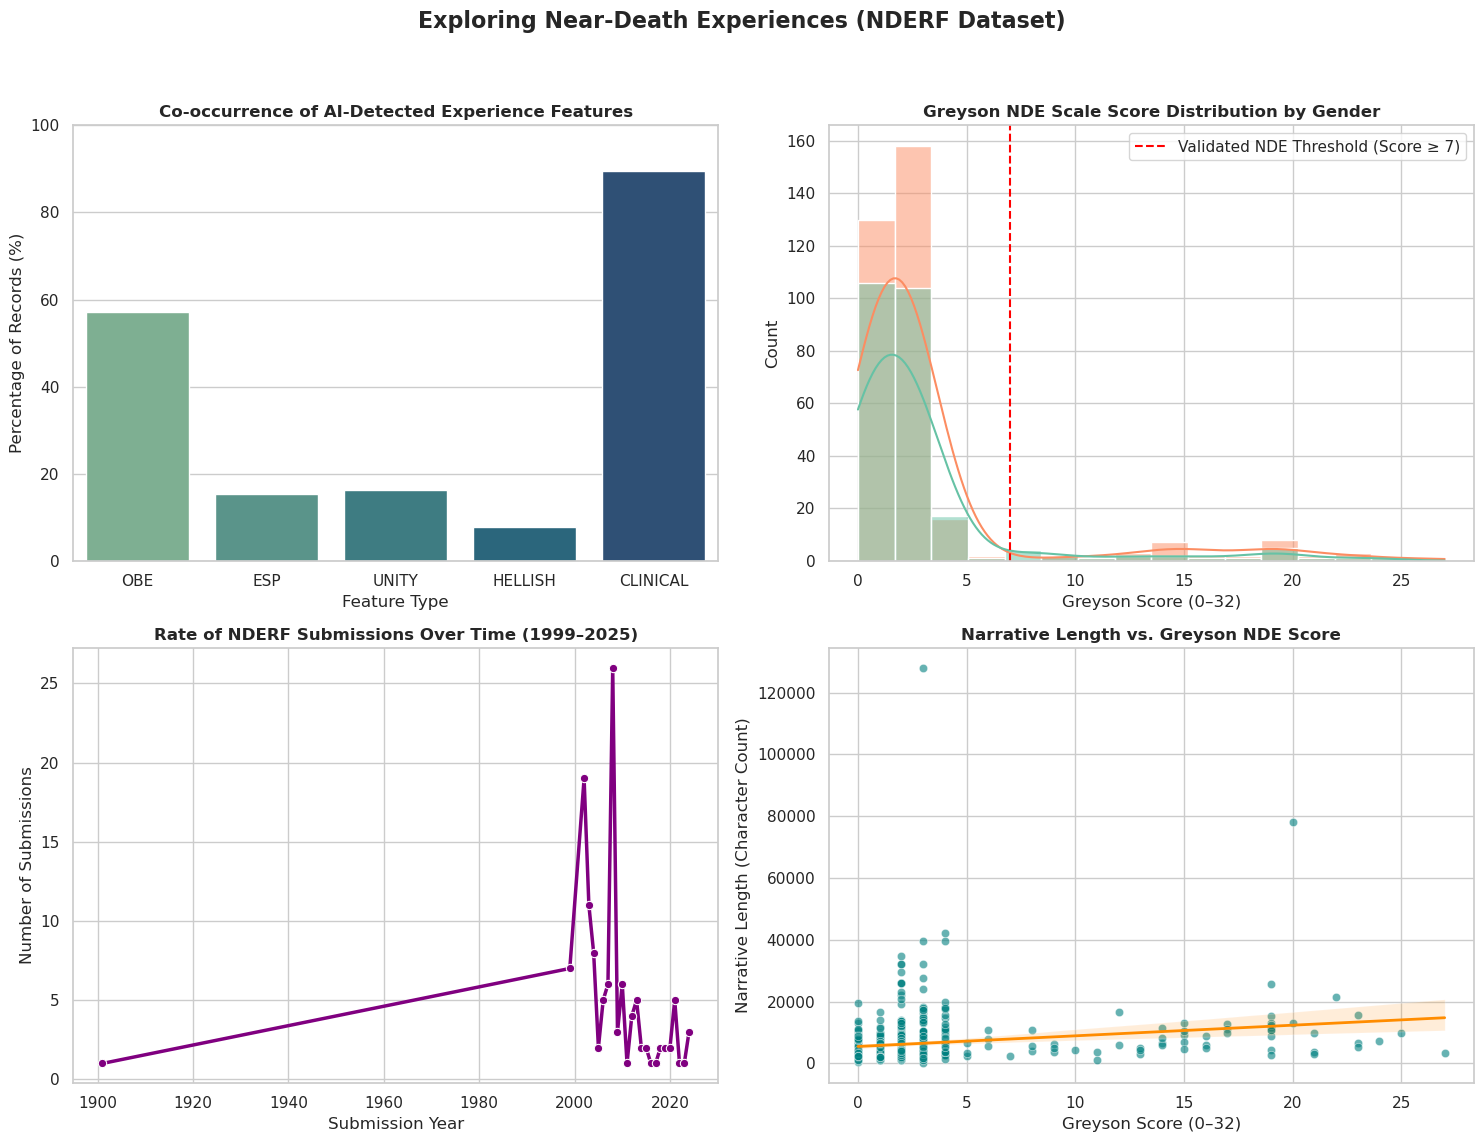

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Load the dataset directly from the TidyTuesday GitHub repository
url = 'https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2026/2026-07-21/nde_experiences.csv'
df = pd.read_csv(url)

print(
    f'Dataset successfully loaded! Shape: {df.shape[0]} rows, {df.shape[1]} columns'
)
print(df.head())

# 2. Set up the plotting theme
sns.set_theme(style='whitegrid')
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
fig.suptitle(
    'Exploring Near-Death Experiences (NDERF Dataset)',
    fontsize=16,
    fontweight='bold',
)

# --- Subplot 1: AI-Detected Feature Co-occurrence ---
features = ['ai_obe', 'ai_esp', 'ai_unity', 'ai_hellish', 'ai_clinical']
feature_means = (df[features].mean() * 100).reset_index()
feature_means.columns = ['Feature', 'Percentage']
feature_means['Feature'] = feature_means['Feature'].str.replace('ai_', '').str.upper()

sns.barplot(
    data=feature_means,
    x='Feature',
    y='Percentage',
    ax=axes[0, 0],
    palette='crest',
)
axes[0, 0].set_title(
    'Co-occurrence of AI-Detected Experience Features', fontweight='bold'
)
axes[0, 0].set_ylabel('Percentage of Records (%)')
axes[0, 0].set_xlabel('Feature Type')
axes[0, 0].set_ylim(0, 100)

# --- Subplot 2: Greyson Score Distribution by Gender ---
sns.histplot(
    data=df,
    x='greyson_score',
    hue='gender',
    kde=True,
    ax=axes[0, 1],
    palette='Set2',
    bins=16,
    alpha=0.5,
)
axes[0, 1].axvline(
    7, color='red', linestyle='--', label='Validated NDE Threshold (Score ≥ 7)'
)
axes[0, 1].set_title('Greyson NDE Scale Score Distribution by Gender', fontweight='bold')
axes[0, 1].set_xlabel('Greyson Score (0–32)')
axes[0, 1].set_ylabel('Count')
axes[0, 1].legend()

# --- Subplot 3: NDERF Submissions Over Time ---
df['post_date'] = pd.to_datetime(df['post_date'], errors='coerce')
df['year'] = df['post_date'].dt.year
yearly_subs = df.groupby('year').size().reset_index(name='count')

sns.lineplot(
    data=yearly_subs,
    x='year',
    y='count',
    ax=axes[1, 0],
    marker='o',
    color='purple',
    linewidth=2.5,
)
axes[1, 0].set_title('Rate of NDERF Submissions Over Time (1999–2025)', fontweight='bold')
axes[1, 0].set_xlabel('Submission Year')
axes[1, 0].set_ylabel('Number of Submissions')

# --- Subplot 4: Narrative Length vs. Greyson Score ---
sns.scatterplot(
    data=df,
    x='greyson_score',
    y='narrative_length',
    ax=axes[1, 1],
    alpha=0.6,
    color='teal',
)
sns.regplot(
    data=df,
    x='greyson_score',
    y='narrative_length',
    ax=axes[1, 1],
    scatter=False,
    color='darkorange',
    line_kws={'linewidth': 2},
)
axes[1, 1].set_title('Narrative Length vs. Greyson NDE Score', fontweight='bold')
axes[1, 1].set_xlabel('Greyson Score (0–32)')
axes[1, 1].set_ylabel('Narrative Length (Character Count)')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()